In [ ]:
import os, sys, json, time, subprocess
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import requests
import numpy as np, cv2
import matplotlib.pyplot as plt
import onnxruntime as ort

TEST_IMG = "datasets/yolo_poly/test/images/car_013.jpg"
COLORS = {"airplane": (47, 125, 225), "boat": (17, 165, 154), "car": (232, 88, 45), "motorcycle": (166, 79, 214)}
print("ภาพทดสอบ:", TEST_IMG)

ภาพทดสอบ: datasets/yolo_poly/test/images/car_013.jpg


In [ ]:
src = open("web/backend/app.py", encoding="utf-8").read()
start = src.index('@app.post("/api/predict")')
end = src.index("# ----", start)
print(src[start:end])

@app.post("/api/predict")
async def predict(
    file: UploadFile = File(..., description="ไฟล์ภาพ jpg/png"),
    conf: float = Form(0.25, description="ความมั่นใจขั้นต่ำ 0-1"),
):
    """รับภาพ 1 ภาพ -> ส่งให้ YOLO (Polygon) -> คืนผลเป็น JSON"""
    


In [ ]:
server = subprocess.Popen([sys.executable, "-m", "uvicorn", "web.backend.app:app", "--port", "8000"],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
for _ in range(60):
    try:
        requests.get("http://localhost:8000/api/health", timeout=1)
        break
    except requests.ConnectionError:
        time.sleep(1)
print("server พร้อมแล้ว -> http://localhost:8000  และ  http://localhost:8000/docs")

server พร้อมแล้ว -> http://localhost:8000  และ  http://localhost:8000/docs


In [ ]:
r = requests.get("http://localhost:8000/api/health")
print("status code:", r.status_code)
print(json.dumps(r.json(), indent=2))

status code: 200
{
  "status": "ok",
  "models": [
    "poly"
  ],
  "classes": [
    "airplane",
    "boat",
    "car",
    "motorcycle"
  ]
}


In [ ]:
with open(TEST_IMG, "rb") as f:
    r = requests.post("http://localhost:8000/api/predict", files={"file": f}, data={"conf": 0.25})
out = r.json()

show = json.loads(json.dumps(out))
for d in show["detections"]:
    d["polygon"] = d["polygon"][:3] + [f"... อีก {len(d['polygon']) - 3} จุด"]
print(json.dumps(show, indent=2, ensure_ascii=False))

{
  "mode": "poly",
  "image_width": 640,
  "image_height": 424,
  "inference_ms": 2160.6,
  "count": 2,
  "top_class": "car",
  "detections": [
    {
      "class_id": 2,
      "class_name": "car",
      "confidence": 0.9354,
      "box": [
        251.7,
        234.5,
        470.2,
        324.3
      ],
      "polygon": [
        [
          462.5,
          300.2
        ],
        [
          461.2,
          301.4
        ],
        [
          461.2,
          302.7
        ],
        "... อีก 189 จุด"
      ]
    },
    {
      "class_id": 2,
      "class_name": "car",
      "confidence": 0.7924,
      "box": [
        450.9,
        206.6,
        640.0,
        354.5
      ],
      "polygon": [
        [
          622.5,
          292.7
        ],
        [
          621.2,
          293.9
        ],
        [
          621.2,
          295.2
        ],
        "... อีก 187 จุด"
      ]
    }
  ]
}


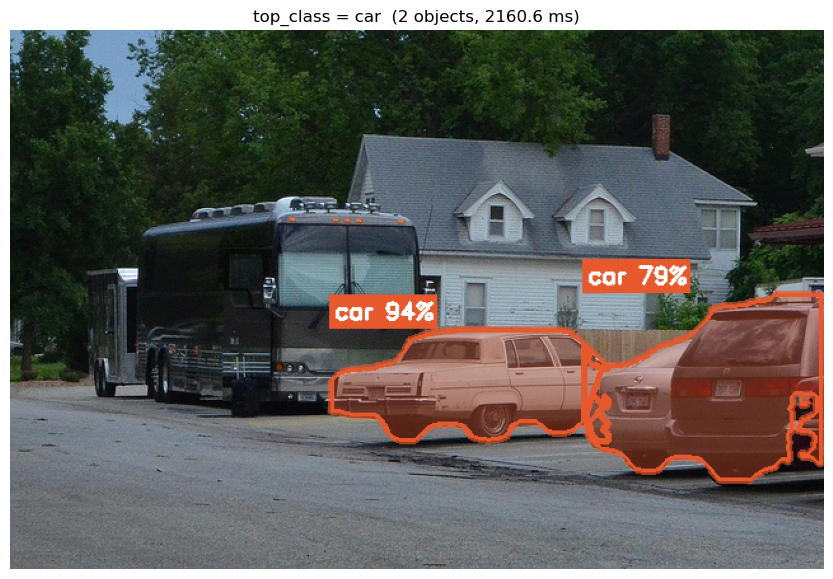

In [ ]:
img = cv2.cvtColor(cv2.imread(TEST_IMG), cv2.COLOR_BGR2RGB)
overlay = img.copy()
for d in reversed(out["detections"]):
    color = COLORS[d["class_name"]]
    pts = np.array(d["polygon"], np.int32)
    cv2.fillPoly(overlay, [pts], color)
    cv2.polylines(img, [pts], True, color, 3)
result = cv2.addWeighted(overlay, 0.35, img, 0.65, 0)
for d in out["detections"]:
    x1, y1 = int(d["box"][0]), int(d["box"][1])
    label = f"{d['class_name']} {d['confidence']*100:.0f}%"
    cv2.rectangle(result, (x1, max(y1 - 26, 0)), (x1 + 12 * len(label), max(y1, 26)), COLORS[d["class_name"]], -1)
    cv2.putText(result, label, (x1 + 4, max(y1 - 7, 19)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)

plt.figure(figsize=(11, 7)); plt.imshow(result); plt.axis("off")
plt.title(f"top_class = {out['top_class']}  ({out['count']} objects, {out['inference_ms']} ms)"); plt.show()

In [ ]:
print(open("web/frontend/config.js", encoding="utf-8").read())

// =====================================================================
//  config.js : ตั้งค่าว่าหน้าเว็บจะใช้อะไรทำนาย
// =====================================================================
//  INFERENCE:
//    "auto"    = ลองเรียก API (หลังบ้าน) ก่อน ถ้าไม่มี server ให้รันโมเดลในเบราว์เซอร์แทน  <- ค่าเริ่มต้น
//    "api"     = ใช้หลังบ้าน (FastAPI) เท่านั้น
//    "browser" = รันในเบราว์เซอร์เท่านั้น (ใช้ไฟล์ models/*.onnx)
//
//  API_BASE: ที่อยู่ของหลังบ้าน
//    ""  = server เดียวกับที่เปิดหน้าเว็บ (เช่น http://localhost:8000)
//    หรือใส่ URL เต็ม ถ้าหลังบ้านอยู่ที่อื่น เช่น "https://my-backend.onrender.com"
window.INFERENCE = "auto";
window.API_BASE = "";



In [8]:
server.terminate()
print("ปิด server แล้ว")

ปิด server แล้ว


ภาพจริง 640x424  ->  ย่อเป็น 512x339  (scale = 0.800)  ขอบ padX = 0, padY = 86


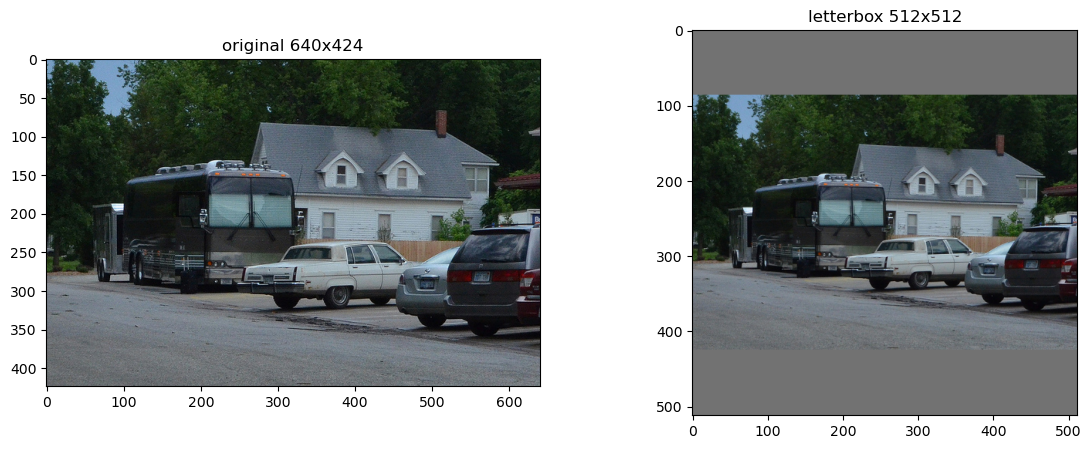

In [ ]:
IMGSZ = 512
img = cv2.cvtColor(cv2.imread(TEST_IMG), cv2.COLOR_BGR2RGB)
h0, w0 = img.shape[:2]

scale = min(IMGSZ / w0, IMGSZ / h0)
nw, nh = round(w0 * scale), round(h0 * scale)
padX = round((IMGSZ - nw) / 2 - 0.1)
padY = round((IMGSZ - nh) / 2 - 0.1)
canvas = np.full((IMGSZ, IMGSZ, 3), 114, np.uint8)
canvas[padY:padY + nh, padX:padX + nw] = cv2.resize(img, (nw, nh))

print(f"ภาพจริง {w0}x{h0}  ->  ย่อเป็น {nw}x{nh}  (scale = {scale:.3f})  ขอบ padX = {padX}, padY = {padY}")
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].imshow(img); ax[0].set_title(f"original {w0}x{h0}")
ax[1].imshow(canvas); ax[1].set_title("letterbox 512x512")
plt.show()

In [ ]:
x = canvas.transpose(2, 0, 1)[None].astype(np.float32) / 255
print("input tensor :", x.shape, f"ค่าต่ำสุด {x.min():.2f} สูงสุด {x.max():.2f}")

sess = ort.InferenceSession("web/frontend/models/poly.onnx")
t0 = time.perf_counter()
out0, out1 = sess.run(None, {"images": x})
print(f"รันโมเดลใช้เวลา {(time.perf_counter() - t0) * 1000:.0f} ms")
print("output0 :", out0.shape, " (กล่อง + คะแนน + สัมประสิทธิ์ mask)")
print("output1 :", out1.shape, " (mask พื้นฐาน 32 แผ่น)")

input tensor : (1, 3, 512, 512) ค่าต่ำสุด 0.00 สูงสุด 1.00
รันโมเดลใช้เวลา 37 ms
output0 : (1, 40, 5376)  (กล่อง + คะแนน + สัมประสิทธิ์ mask)
output1 : (1, 32, 128, 128)  (mask พื้นฐาน 32 แผ่น)


In [ ]:
names = ["airplane", "boat", "car", "motorcycle"]
pred = out0[0].T
boxes, scores, coefs = pred[:, :4], pred[:, 4:8], pred[:, 8:]
cls, conf = scores.argmax(1), scores.max(1)

keep = conf >= 0.25
print(f"กล่องทั้งหมด {len(conf)}  ->  ผ่าน conf >= 0.25 : {keep.sum()} กล่อง")
boxes, cls, conf, coefs = boxes[keep], cls[keep], conf[keep], coefs[keep]
xyxy = np.c_[boxes[:, 0] - boxes[:, 2] / 2, boxes[:, 1] - boxes[:, 3] / 2,
             boxes[:, 0] + boxes[:, 2] / 2, boxes[:, 1] + boxes[:, 3] / 2]

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    return inter / ((a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter)

final = []
for i in conf.argsort()[::-1]:
    if all(cls[j] != cls[i] or iou(xyxy[j], xyxy[i]) < 0.7 for j in final):
        final.append(i)
print(f"หลัง NMS เหลือ {len(final)} วัตถุ")

กล่องทั้งหมด 5376  ->  ผ่าน conf >= 0.25 : 15 กล่อง
หลัง NMS เหลือ 2 วัตถุ


In [ ]:
for i in final:
    b512 = xyxy[i]
    b = (b512 - [padX, padY, padX, padY]) / scale
    print(f"{names[cls[i]]:<10} conf {conf[i]:.3f} | พิกัดบน 512x512 = {b512.round().astype(int).tolist()}"
          f"  ->  บนภาพจริง = {b.round().astype(int).tolist()}")

car        conf 0.847 | พิกัดบน 512x512 = [201, 273, 378, 346]  ->  บนภาพจริง = [251, 234, 472, 325]
car        conf 0.771 | พิกัดบน 512x512 = [360, 254, 512, 370]  ->  บนภาพจริง = [450, 210, 640, 356]


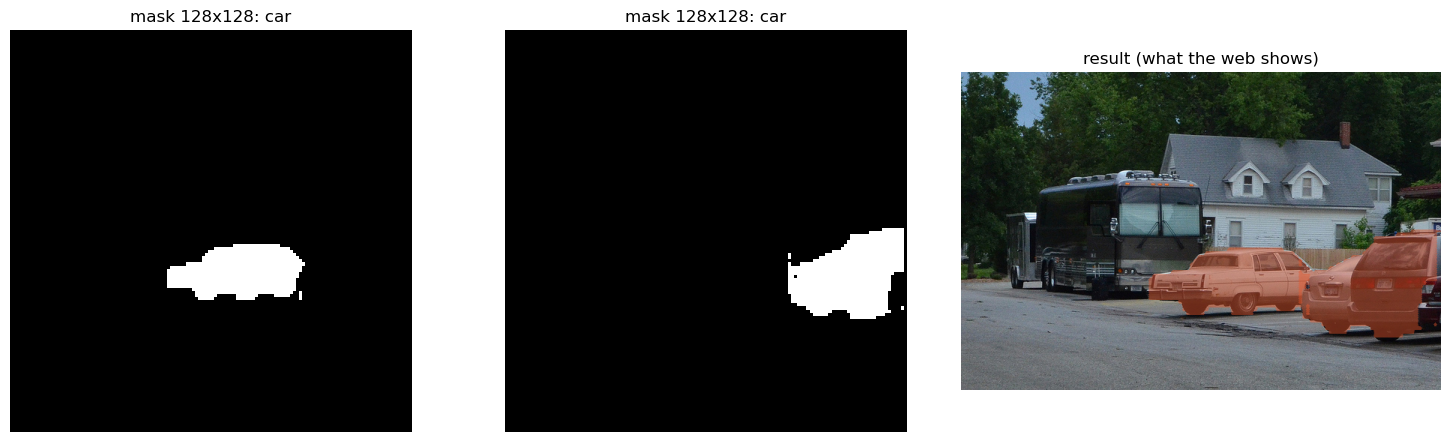

In [ ]:
protos = out1[0]
r = protos.shape[1] / IMGSZ
result = img.copy()
fig, axes = plt.subplots(1, len(final) + 1, figsize=(5 * (len(final) + 1), 4.5))
for k, i in enumerate(final):
    m = np.tensordot(coefs[i], protos, axes=1)
    x1, y1, x2, y2 = (xyxy[i] * r).astype(int)
    crop = np.zeros_like(m, bool)
    crop[max(y1, 0):y2, max(x1, 0):x2] = True
    mask = (m > 0) & crop
    axes[k].imshow(mask, cmap="gray"); axes[k].set_title(f"mask 128x128: {names[cls[i]]}")
    sub = mask[int(padY * r):int((padY + nh) * r), int(padX * r):int((padX + nw) * r)].astype(np.uint8)
    full = cv2.resize(sub, (w0, h0), interpolation=cv2.INTER_LINEAR).astype(bool)
    result[full] = (0.55 * result[full] + 0.45 * np.array(COLORS[names[cls[i]]])).astype(np.uint8)
axes[-1].imshow(result); axes[-1].set_title("result (what the web shows)")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
from ultralytics import YOLO
print("โค้ดของเรา (แบบ infer.js):")
for i in final:
    print(f"   {names[cls[i]]:<10} {conf[i]:.3f}")
res = YOLO("web/frontend/models/poly.onnx", task="segment").predict(TEST_IMG, imgsz=512, conf=0.25, verbose=False)[0]
print("ultralytics (ไฟล์ onnx เดียวกัน):")
for c, s in zip(res.boxes.cls, res.boxes.conf):
    print(f"   {names[int(c)]:<10} {float(s):.3f}")

โค้ดของเรา (แบบ infer.js):
   car        0.847
   car        0.771
Loading web/frontend/models/poly.onnx for ONNX Runtime inference...


Using ONNX Runtime 1.31.0 with CPUExecutionProvider


ultralytics (ไฟล์ onnx เดียวกัน):
   car        0.847
   car        0.771


In [ ]:
DEPLOY = False
if DEPLOY:
    !{sys.executable} scripts/05_deploy_huggingface.py --space witthaya22/final-dip
else:
    print("ยังไม่ deploy (ตั้ง DEPLOY = True แล้วรันใหม่)")

ยังไม่ deploy (ตั้ง DEPLOY = True แล้วรันใหม่)


In [ ]:
URL = "https://witthaya22-final-dip.static.hf.space"
for f in ["", "app.js", "infer.js", "config.js", "style.css", "models/poly.onnx"]:
    r = requests.get(f"{URL}/{f}", timeout=60)
    print(f"{r.status_code}  {len(r.content) / 1e3:>9,.0f} KB   /{f}")
print("\nเปิดเว็บ:", URL)

200          4 KB   /


200         12 KB   /app.js


200          9 KB   /infer.js


200          1 KB   /config.js


200          4 KB   /style.css


200     11,009 KB   /models/poly.onnx

เปิดเว็บ: https://witthaya22-final-dip.static.hf.space
